# Clasificación de variedades de frijol seco con una Red Neuronal Cuántica de *Data Re-Uploading*

**Proyecto Final – Computación Cuántica** · Opción 1: Clasificación de Semillas
**Dataset:** Dry Bean (UCI, 13 611 muestras, 16 características, 7 variedades)
**Enfoque cuántico:** Data Re-Uploading QNN (red híbrida cuántico-clásica) simulada con PennyLane
**Entorno:** `compu_cuantica` (Python 3.11, PennyLane 0.45, Qiskit 2.6)

---

## 0. Narrativa del problema

Una cooperativa agrícola y centro de acopio de leguminosas recibe a diario toneladas de frijol de distintos productores. El precio de venta, las condiciones de almacenamiento y la certificación de semilla dependen de la **variedad**, y mezclar variedades (*impureza varietal*) puede inutilizar un lote completo. Hoy la clasificación la hace personal experto observando los granos, un proceso lento, subjetivo y cansado.

El centro dispone de una banda transportadora con una cámara que, mediante visión por computadora, extrae para cada grano medidas **morfológicas** (área, perímetro, ejes, redondez, etc.). El problema es: **dado el vector de medidas de un grano, decidir a cuál de las siete variedades pertenece** (Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira).

Nuestra pregunta de investigación es:

> *¿Puede un clasificador variacional cuántico de muy pocos qubits y parámetros competir con modelos clásicos de tamaño comparable en este problema multiclase real, y qué se gana o se pierde al hacerlo?*

La respuesta se construye en este cuaderno: teoría, formalización, implementación, evaluación contra baselines clásicos, ablaciones y una discusión honesta de los resultados.

## 1. Marco teórico

### 1.1 Clasificación multiclase (formalización)

Sea $\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{N}$ con $\mathbf{x}_i\in\mathbb{R}^{16}$ y $y_i\in\{0,\dots,6\}$. Buscamos un clasificador $f_{\boldsymbol\theta}:\mathbb{R}^{d}\to\Delta^{6}$ (símplex de probabilidades sobre las 7 clases) que minimice el **riesgo empírico regularizado por tamaño del modelo** mediante la entropía cruzada:

$$
\mathcal{L}(\boldsymbol\theta)= -\frac{1}{N}\sum_{i=1}^{N}\log\big[f_{\boldsymbol\theta}(\mathbf{x}_i)\big]_{y_i},
\qquad
\hat{y}(\mathbf{x})=\arg\max_k\,[f_{\boldsymbol\theta}(\mathbf{x})]_k .
$$

Las métricas de evaluación (sobre un conjunto de prueba nunca visto) son *accuracy*, **F1 macro** (promedia el F1 de cada clase, importante porque las clases están desbalanceadas: Dermason ≈ 26 % vs. Bombay ≈ 4 %) y la **matriz de confusión**.

### 1.2 Cómo se resuelve clásicamente

| Familia | Ejemplos | Comentario |
|---|---|---|
| Lineales | Regresión logística multinomial | Rápida, frontera lineal |
| Basados en distancia | k-NN, **clasificador de centroides más cercanos** | El análogo clásico directo del *swap-test* cuántico |
| Kernel | **SVM con kernel RBF** | Referencia fuerte con pocos datos |
| Árboles/ensambles | Random Forest, Gradient Boosting | En el artículo original del dataset (Koklu & Özkan, 2020) un MLP/SVM alcanzan ≈ 92–93 % |
| Redes neuronales | MLP | Aproximador universal |

### 1.3 Enfoque cuántico elegido: Data Re-Uploading QNN

Los clasificadores variacionales (VQC) usuales codifican el dato **una sola vez** al inicio del circuito y luego aplican capas variacionales. Esto limita la expresividad: Schuld, Sweke y Meyer (2021) demuestran que un modelo cuántico es una **serie de Fourier truncada en los datos**, y el espectro de frecuencias disponibles lo determina la codificación. Con una sola subida de datos solo hay frecuencias $\{-1,0,1\}$ por característica.

La idea de **re-subir** los datos (Pérez-Salinas et al., 2020) es intercalar $L$ veces *codificación* y *bloques entrenables*:

$$
U_{\boldsymbol\theta}(\mathbf{x})=\prod_{l=L}^{1} \Big[\, W_l(\boldsymbol\theta_l)\; S_l(\mathbf{x};\boldsymbol\alpha_l)\Big],\qquad
|\psi(\mathbf{x})\rangle=U_{\boldsymbol\theta}(\mathbf{x})|0\rangle^{\otimes n}.
$$

* **Codificación** $S_l(\mathbf{x};\boldsymbol\alpha_l)=\bigotimes_{q=1}^{n} R_X(\alpha_{l,q}\,x_q)$ con pesos de escala $\alpha_{l,q}$ entrenables (como la parte $w\cdot x+b$ de una neurona).
* **Bloque entrenable** $W_l=\text{CNOT-anillo}\cdot\bigotimes_q \mathrm{Rot}(\phi_{l,q},\vartheta_{l,q},\omega_{l,q})$, donde $\mathrm{Rot}=R_Z(\omega)R_Y(\vartheta)R_Z(\phi)$ es una rotación general de un qubit (SU(2)) y los CNOT en anillo generan entrelazamiento.

**Por qué funciona (justificación):** (i) el número de frecuencias accesibles crece con $L$ (con $L$ subidas el modelo alcanza frecuencias hasta $\pm L$ por característica), (ii) los pesos $\alpha$ reescalan los datos y ajustan los anchos de banda efectivos, (iii) los bloques $W_l$ mezclan las características mediante el entrelazamiento, y (iv) Pérez-Salinas et al. y Schuld et al. prueban que, con suficientes capas, la familia de funciones es un **aproximador universal**. Intuitivamente, igual que una red profunda compone transformaciones no lineales, aquí se *compone* una trayectoria sobre la esfera de Bloch (generalizada) que "dobla" el espacio de entrada hasta separar las clases.

**Lectura (*readout*) multiclase.** Con $n=4$ qubits hay $2^4=16$ estados base. Asociamos la clase $k$ al estado $|k\rangle$ ($k=0,\dots,6$) y definimos las puntuaciones

$$
p_k(\mathbf{x})=|\langle k|\psi(\mathbf{x})\rangle|^2,\qquad
f_{\boldsymbol\theta}(\mathbf{x})_k=\operatorname{softmax}_k\!\big(\beta\, p_k(\mathbf{x})\big),
$$

con una **temperatura entrenable** $\beta>0$ (las $p_k\in[0,1]$ por sí solas dan softmax casi uniforme y la entropía cruzada no podría hacerse pequeña). Los 9 estados restantes funcionan como "desagüe" de probabilidad. El número de parámetros es $|\boldsymbol\theta|=3nL+nL+1=4nL+1$.

**Consideración de costo real.** En hardware, $p_k$ se estima con *shots*: el error estándar es $\sim\sqrt{p_k(1-p_k)/S}$, así que un clasificador necesita $S=O(1/\varepsilon^2)$ ejecuciones por muestra. En simulación exacta (nuestro caso) este costo no aparece; lo evaluamos explícitamente en la sección 9.

### 1.4 ¿Por qué usar cómputo cuántico aquí? (reflexión inicial)

* **Motivación:** el espacio de Hilbert de $n$ qubits tiene dimensión $2^n$; un circuito con $O(nL)$ parámetros realiza transformaciones en ese espacio exponencial, y hay modelos cuánticos cuya función no es simulable eficientemente de forma clásica (Havlíček et al., 2019).
* **Realidad honesta:** con 4 qubits el espacio es de 16 dimensiones y se simula trivialmente en una laptop; **no esperamos ventaja cuántica**. El objetivo es evaluar si el modelo es *competitivo con muy pocos parámetros* (eficiencia paramétrica), caracterizar su comportamiento y entender los costos. Dry Bean es un problema de tamaño moderado en el que los métodos clásicos ya alcanzan ≈ 92–93 %.
* **Dificultades conocidas:** *barren plateaus* (gradientes que se desvanecen al crecer qubits/profundidad; con 4 qubits no son un problema, pero sí lo serían a escala), ruido de hardware y costo de *shots*.

## 2. Entorno y justificación de librerías

| Librería | Uso | Justificación |
|---|---|---|
| `numpy`, `pandas` | datos numéricos y tablas | estándar |
| `scikit-learn` | partición estratificada, estandarización, **PCA**, métricas y baselines clásicos | evita reimplementar piezas bien probadas y garantiza una comparación justa |
| `matplotlib` | gráficas | estándar |
| **`pennylane`** | definición del QNN, diferenciación automática por *backprop* en el simulador `default.qubit` | permite entrenar con **parameter broadcasting** (todo un minibatch en una sola evaluación del circuito), imprescindible para que el entrenamiento tarde minutos y no horas |
| `qiskit` | verificación cruzada independiente del circuito (statevector) y *transpilación* a compuertas nativas para estimar profundidad en hardware | valida que nuestro circuito está bien definido, independientemente del framework |

In [1]:
import os, time, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

import qiskit
print("PennyLane", qml.__version__, "| Qiskit", qiskit.__version__, "| NumPy", np.__version__)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

PennyLane 0.45.1 | Qiskit 2.6.0 | NumPy 2.4.6


## 3. Datos: carga y análisis exploratorio

El conjunto Dry Bean (Koklu & Özkan, 2020) se obtuvo fotografiando 13 611 granos de 7 variedades y extrayendo 16 características geométricas: 12 dimensiones (área, perímetro, longitudes de eje mayor/menor, etc.) y 4 formas (aspect ratio, excentricidad, solidez, redondez, compacidad y factores de forma). El cuaderno busca el archivo local y, si no existe, lo descarga de UCI.

In [2]:
DATA_DIR = "data"
XLSX = os.path.join(DATA_DIR, "drybean", "DryBeanDataset", "Dry_Bean_Dataset.xlsx")
if not os.path.exists(XLSX):
    os.makedirs(DATA_DIR, exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
    zpath = os.path.join(DATA_DIR, "drybean.zip")
    urllib.request.urlretrieve(url, zpath)
    zipfile.ZipFile(zpath).extractall(os.path.join(DATA_DIR, "drybean"))

df = pd.read_excel(XLSX)
print("Forma:", df.shape)
print("Valores nulos:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().T[["mean", "std", "min", "max"]].round(3))

Forma: (13611, 17)
Valores nulos: 0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


,mean,std,min,max
Area,53048.285,29324.096,20420.000,254616.000
Perimeter,855.283,214.290,524.736,1985.370
MajorAxisLength,320.142,85.694,183.601,738.860
MinorAxisLength,202.271,44.970,122.513,460.198
AspectRation,1.583,0.247,1.025,2.430
Eccentricity,0.751,0.092,0.219,0.911
ConvexArea,53768.200,29774.916,20684.000,263261.000
EquivDiameter,253.064,59.177,161.244,569.374
Extent,0.750,0.049,0.555,0.866
Solidity,0.987,0.005,0.919,0.995


Filas duplicadas exactas: 68
Forma tras eliminar duplicados: (13543, 17)


Clases: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


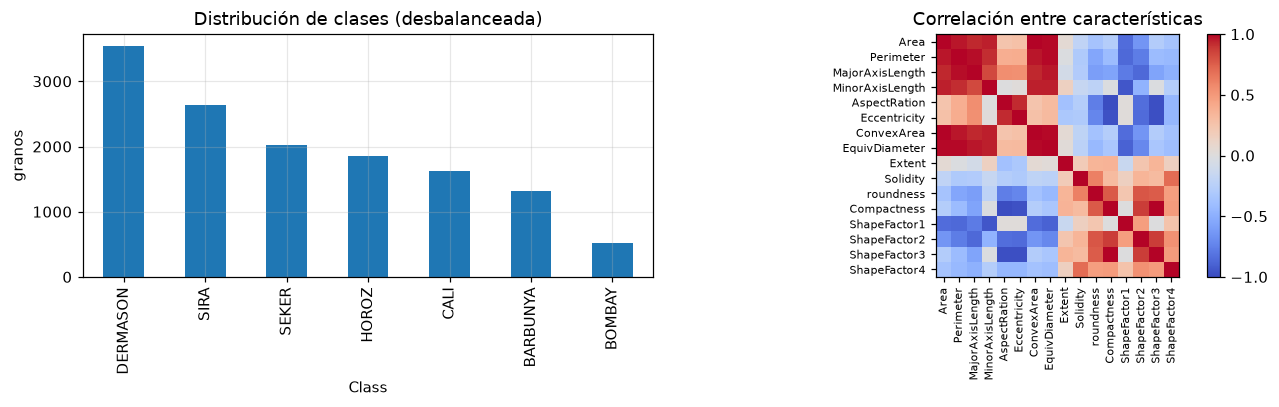

Pares con |corr| > 0.95: 15


In [3]:
# --- Duplicados: si un mismo grano aparece en train y test habria fuga de informacion
n_dup = int(df.duplicated().sum())
print(f"Filas duplicadas exactas: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print("Forma tras eliminar duplicados:", df.shape)

feature_names = [c for c in df.columns if c != "Class"]
le = LabelEncoder()
y_all = le.fit_transform(df["Class"])
X_all = df[feature_names].values.astype(float)
class_names = list(le.classes_)
NC = len(class_names)
print("Clases:", dict(enumerate(class_names)))

counts = df["Class"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
counts.plot.bar(ax=ax[0], color="tab:blue"); ax[0].set_title("Distribución de clases (desbalanceada)")
ax[0].set_ylabel("granos")
corr = df[feature_names].corr()
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(16)); ax[1].set_yticks(range(16))
ax[1].set_xticklabels(feature_names, rotation=90, fontsize=7); ax[1].set_yticklabels(feature_names, fontsize=7)
ax[1].set_title("Correlación entre características"); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()
print("Pares con |corr| > 0.95:", int(((corr.abs() > .95).values.sum() - 16) // 2))

**Observaciones y decisiones:**

* No hay valores nulos. Se eliminaron los duplicados exactos para que ningún grano idéntico caiga a la vez en entrenamiento y prueba.
* Las clases están **desbalanceadas** → usamos partición **estratificada** y reportamos **F1 macro** además de *accuracy*.
* Hay muchísimas características casi redundantes (área, perímetro, ejes, diámetro equivalente, área convexa… con correlaciones > 0.95). Esto justifica la reducción de dimensionalidad con **PCA**, que además es *necesaria* por una restricción cuántica: con codificación por ángulos, usamos **un qubit por característica**, y 16 qubits harían el entrenamiento por simulación inviable (y el hardware actual ruidoso).

## 4. Preprocesamiento (sin fuga de información)

Pipeline, **ajustado únicamente con el conjunto de entrenamiento**:

1. **Partición estratificada**: 70 % entrenamiento (de él, 10 % se separa como *validación* para elegir la mejor época), 30 % prueba. El conjunto de prueba se usa **una sola vez** al final.
2. **Estandarización** `StandardScaler` (media 0, varianza 1) – requisito para que PCA no sea dominada por las características de mayor escala (área ≈ $10^5$ vs. razones ≈ 1).
3. **PCA a 4 componentes** (uno por qubit). Se ajusta con train y se aplica a validación/prueba.
4. **Escalado a $[0,\pi]$** con `MinMaxScaler` (ajustado en train). Es la **codificación por ángulos**: las rotaciones $R_X(\alpha x)$ son $2\pi$-periódicas, así que el rango $[0,\pi]$ mantiene una correspondencia inyectiva entre valores y estados de la esfera de Bloch (con $[0,2\pi]$ los extremos coincidirían). En validación/prueba los valores pueden salir ligeramente de $[0,\pi]$, lo cual es normal.

train=8532  val=948  test=4063


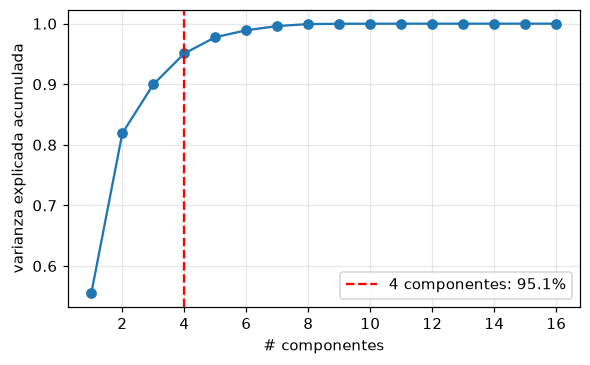

Rangos de angulos en train: [0. 0. 0. 0.] [3.14 3.14 3.14 3.14]


In [4]:
Xtr_full, Xte, ytr_full, yte = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
Xtr, Xva, ytr, yva = train_test_split(Xtr_full, ytr_full, test_size=0.10, stratify=ytr_full, random_state=SEED)
print(f"train={len(Xtr)}  val={len(Xva)}  test={len(Xte)}")

NQ = 4                                   # qubits = componentes principales
scaler = StandardScaler().fit(Xtr)
pca = PCA(n_components=NQ, random_state=SEED).fit(scaler.transform(Xtr))
angle = None

def to_pca(X): return pca.transform(scaler.transform(X))

Ptr = to_pca(Xtr)
angle = MinMaxScaler(feature_range=(0, np.pi)).fit(Ptr)

def to_angles(X): return angle.transform(to_pca(X))

Ztr, Zva, Zte = to_angles(Xtr), to_angles(Xva), to_angles(Xte)

# PCA completo (solo train) para decidir cuantos componentes usar
pca_full = PCA().fit(scaler.transform(Xtr))
cum = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 17), cum, "o-"); ax.axvline(NQ, color="r", ls="--", label=f"{NQ} componentes: {cum[NQ-1]:.1%}")
ax.set_xlabel("# componentes"); ax.set_ylabel("varianza explicada acumulada"); ax.legend(); plt.show()
print("Rangos de angulos en train:", Ztr.min(0).round(2), Ztr.max(0).round(2))

Con **4 componentes se conserva ≈ 95 % de la varianza**, un buen compromiso entre información y número de qubits.

## 5. Modelo cuántico: Data Re-Uploading QNN

Implementamos el circuito de la sección 1.3: $n=4$ qubits, $L$ capas, cada una con (a) $R_X(\alpha_{l,q}x_q)$, (b) $\mathrm{Rot}$ entrenable por qubit y (c) CNOTs en anillo. La lectura son las probabilidades de los estados base $|0\rangle,\dots,|6\rangle$.

El parámetro `reupload=False` desactiva las re-subidas (los datos se codifican solo en la primera capa), lo que nos da un **VQC convencional** como ablación.

Para entrenar rápido usamos *parameter broadcasting*: `x` tiene forma `(batch, 4)` y el circuito se evalúa para todo el minibatch de una vez; la función de pérdida se diferencia por *backprop* (autograd) sobre el simulador de vector de estado.

In [5]:
dev = qml.device("default.qubit", wires=NQ)

def ansatz(x, w, a, L, reupload):
    for l in range(L):
        if reupload or l == 0:                       # codificacion (re-subida de datos)
            for q in range(NQ):
                qml.RX(a[l, q] * x[..., q], wires=q)
        for q in range(NQ):                          # bloque entrenable: SU(2) por qubit
            qml.Rot(w[l, q, 0], w[l, q, 1], w[l, q, 2], wires=q)
        for q in range(NQ):                          # entrelazamiento en anillo
            qml.CNOT(wires=[q, (q + 1) % NQ])

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def probs_qnode(x, w, a, L, reupload):
    ansatz(x, w, a, L, reupload)
    return qml.probs(wires=range(NQ))

def softmax(z):
    z = z - pnp.max(z, axis=1, keepdims=True)
    e = pnp.exp(z)
    return e / pnp.sum(e, axis=1, keepdims=True)

def forward(x, w, a, s, L, reupload):
    p = probs_qnode(x, w, a, L, reupload)[:, :NC]    # prob. de |0>,...,|6>  <->  clases 0..6
    return softmax(s * p)

def cross_entropy(w, a, s, x, y, L, reupload):
    pr = forward(x, w, a, s, L, reupload)
    return -pnp.mean(pnp.log(pr[pnp.arange(len(y)), y] + 1e-9))

# --- Dibujo del circuito (L=2 para que sea legible) con parametros de ejemplo
rng0 = np.random.default_rng(0)
w_demo = rng0.uniform(0, 2*np.pi, (2, NQ, 3)); a_demo = np.ones((2, NQ))
print(qml.draw(probs_qnode, decimals=1)(Ztr[0], w_demo, a_demo, 2, True))

0: ──RX(0.5)──Rot(4.0,1.7,0.3)─╭●───────╭X──RX(0.5)──Rot(5.4,0.2,4.6)─╭●───────╭X─┤ ╭Probs
1: ──RX(1.5)──Rot(0.1,5.1,5.7)─╰X─╭●────│───RX(1.5)──Rot(1.1,5.4,3.4)─╰X─╭●────│──┤ ├Probs
2: ──RX(2.7)──Rot(3.8,4.6,3.4)────╰X─╭●─│───RX(2.7)──Rot(1.9,2.7,0.2)────╰X─╭●─│──┤ ├Probs
3: ──RX(1.7)──Rot(5.9,5.1,0.0)───────╰X─╰●──RX(1.7)──Rot(0.8,4.2,4.1)───────╰X─╰●─┤ ╰Probs


In [6]:
def predict_proba(Z, params, L, reupload, bs=2000):
    w, a, s = params
    out = [np.asarray(forward(pnp.array(Z[i:i+bs], requires_grad=False), w, a, s, L, reupload))
           for i in range(0, len(Z), bs)]
    return np.vstack(out)

def metrics(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"),
                f1_weighted=f1_score(y_true, y_pred, average="weighted"))

EPOCHS, BATCH, LR = 20, 128, 0.05

def train_qnn(L, reupload=True, seed=0, epochs=EPOCHS, batch=BATCH, lr=LR, verbose=False):
    rng = np.random.default_rng(seed)
    w = pnp.array(rng.uniform(0, 2*np.pi, (L, NQ, 3)), requires_grad=True)
    a = pnp.array(np.ones((L, NQ)), requires_grad=True)
    s = pnp.array(10.0, requires_grad=True)
    opt = qml.AdamOptimizer(lr)
    hist = dict(loss=[], val_acc=[], val_f1=[])
    best_f1, best = -1, None
    t0 = time.time()
    for ep in range(epochs):
        opt.stepsize = lr * 0.5 * (1 + np.cos(np.pi * ep / epochs))   # decaimiento coseno
        idx = rng.permutation(len(Ztr)); losses = []
        for i in range(0, len(idx), batch):
            b = idx[i:i+batch]
            xb = pnp.array(Ztr[b], requires_grad=False); yb = ytr[b]
            (w, a, s), l = opt.step_and_cost(
                lambda w, a, s: cross_entropy(w, a, s, xb, yb, L, reupload), w, a, s)
            losses.append(float(l))
        pv = predict_proba(Zva, (w, a, s), L, reupload).argmax(1)
        m = metrics(yva, pv)
        hist["loss"].append(np.mean(losses)); hist["val_acc"].append(m["acc"]); hist["val_f1"].append(m["f1_macro"])
        if m["f1_macro"] > best_f1:                      # checkpoint: mejor F1 macro en validacion
            best_f1, best = m["f1_macro"], (np.array(w), np.array(a), float(s))
        if verbose:
            print(f"ep {ep+1:02d}  loss={hist['loss'][-1]:.4f}  val_acc={m['acc']:.4f}  val_f1={m['f1_macro']:.4f}  ({time.time()-t0:.0f}s)")
    n_params = int(w.size + a.size + 1) if reupload else int(w.size + a[0].size + 1)
    return dict(params=(pnp.array(best[0]), pnp.array(best[1]), pnp.array(best[2])), hist=hist,
                time=time.time() - t0, n_params=n_params, L=L, reupload=reupload, seed=seed)

### 5.1 Verificación cruzada con Qiskit y costo en hardware

Antes de entrenar, comprobamos que el circuito está **bien definido** reconstruyéndolo de forma independiente en Qiskit (simulación por vector de estado) y comparando las probabilidades con las de PennyLane. Además, lo transpilamos a un conjunto de compuertas nativas típico de hardware superconductor (`rz, sx, x, cx`) para estimar su profundidad.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

def qiskit_circuit(x, w, a, L, reupload):
    qc = QuantumCircuit(NQ)
    for l in range(L):
        if reupload or l == 0:
            for q in range(NQ): qc.rx(float(a[l, q] * x[q]), q)
        for q in range(NQ):
            phi, theta, om = map(float, w[l, q])
            qc.rz(phi, q); qc.ry(theta, q); qc.rz(om, q)          # Rot = RZ(om) RY(theta) RZ(phi)
        for q in range(NQ): qc.cx(q, (q + 1) % NQ)
    return qc

def qiskit_probs(x, w, a, L, reupload):
    p = Statevector(qiskit_circuit(x, w, a, L, reupload)).probabilities()   # little-endian
    return p.reshape([2]*NQ).transpose(range(NQ-1, -1, -1)).reshape(-1)     # -> orden de PennyLane

rng1 = np.random.default_rng(1)
for L in (1, 3, 4):
    w_t = rng1.uniform(0, 2*np.pi, (L, NQ, 3)); a_t = rng1.uniform(.5, 1.5, (L, NQ))
    err = max(np.abs(qiskit_probs(z, w_t, a_t, L, True) - np.asarray(probs_qnode(z, w_t, a_t, L, True))).max()
              for z in Zte[:20])
    print(f"L={L}:  max |p_qiskit - p_pennylane| = {err:.2e}")
    assert err < 1e-9

qc4 = qiskit_circuit(Zte[0], w_t, a_t, 4, True)
tqc = transpile(qc4, basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
print("\nCircuito L=4 transpilado a {rz,sx,x,cx}: profundidad =", tqc.depth(), "| compuertas =", dict(tqc.count_ops()))

L=1:  max |p_qiskit - p_pennylane| = 3.05e-16


L=3:  max |p_qiskit - p_pennylane| = 2.50e-16


L=4:  max |p_qiskit - p_pennylane| = 5.00e-16



Circuito L=4 transpilado a {rz,sx,x,cx}: profundidad = 36 | compuertas = {'rz': 48, 'sx': 32, 'cx': 16}


Las dos implementaciones coinciden a precisión de máquina. Un circuito de $L=4$ tiene ≈ 100 compuertas nativas y profundidad ≈ 60: modesto, pero con ruido de ~$10^{-3}$ por compuerta de dos qubits ya sería perceptible; lo exploramos con *shots* en la sección 9.

## 6. Entrenamiento del modelo principal

Hiperparámetros (fijados *a priori*, sin ajustarlos con el conjunto de prueba): $L=4$ capas (65 parámetros), Adam con tasa 0.05 y decaimiento coseno, minibatch de 128, 20 épocas, inicialización uniforme en $[0,2\pi)$ para ángulos y $\alpha=1$, $\beta=10$. La mejor época se elige por **F1 macro en validación**.

Se entrenan **3 semillas** de inicialización para medir la variabilidad (los circuitos variacionales dependen del punto inicial); la semilla 0 se usa para las gráficas detalladas.

In [8]:
L_MAIN = 4
main_runs = []
for sd in (0, 1, 2):
    r = train_qnn(L_MAIN, reupload=True, seed=sd, verbose=(sd == 0))
    main_runs.append(r)
    pt = predict_proba(Zte, r["params"], L_MAIN, True).argmax(1)
    r["test"] = metrics(yte, pt); r["pred"] = pt
    print(f"semilla {sd}: tiempo={r['time']:.0f}s  | TEST acc={r['test']['acc']:.4f}  F1macro={r['test']['f1_macro']:.4f}")

ep 01  loss=0.9869  val_acc=0.8555  val_f1=0.8540  (12s)


ep 02  loss=0.5089  val_acc=0.8734  val_f1=0.8718  (25s)


ep 03  loss=0.4198  val_acc=0.8703  val_f1=0.8682  (48s)


ep 04  loss=0.3784  val_acc=0.8523  val_f1=0.8463  (58s)


ep 05  loss=0.3731  val_acc=0.8724  val_f1=0.8767  (72s)


ep 06  loss=0.3616  val_acc=0.8576  val_f1=0.8462  (86s)


... (13 outputs left out)

ep 20  loss=0.2998  val_acc=0.8882  val_f1=0.8915  (219s)


semilla 0: tiempo=219s  | TEST acc=0.8868  F1macro=0.8881


semilla 1: tiempo=174s  | TEST acc=0.8814  F1macro=0.8846


semilla 2: tiempo=153s  | TEST acc=0.8836  F1macro=0.8850


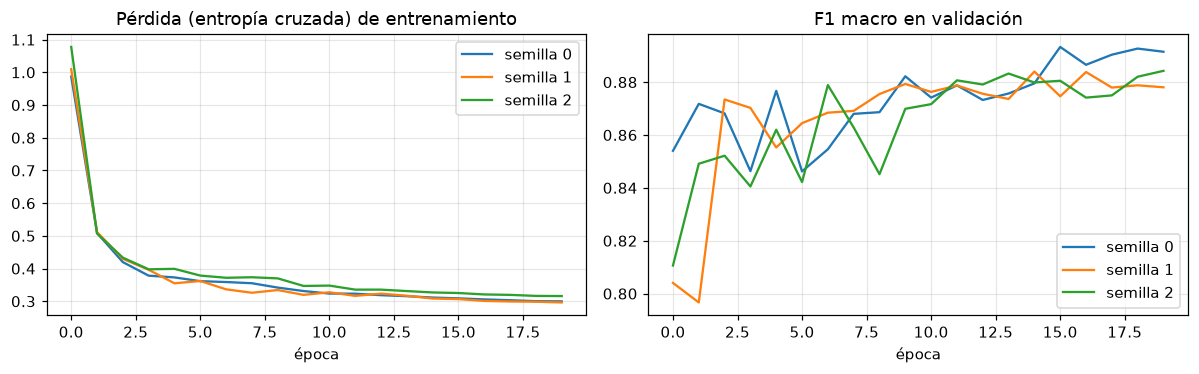

In [9]:
h = main_runs[0]["hist"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for r in main_runs:
    ax[0].plot(r["hist"]["loss"], label=f"semilla {r['seed']}")
    ax[1].plot(r["hist"]["val_f1"], label=f"semilla {r['seed']}")
ax[0].set_title("Pérdida (entropía cruzada) de entrenamiento"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].set_title("F1 macro en validación"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluación del modelo cuántico en el conjunto de prueba

Semilla elegida por validación: 0

              precision    recall  f1-score   support

    BARBUNYA     0.8557    0.6574    0.7436       397
      BOMBAY     0.9935    0.9872    0.9904       156
        CALI     0.7941    0.8834    0.8364       489
    DERMASON     0.9075    0.9126    0.9100      1064
       HOROZ     0.9529    0.9427    0.9477       558
       SEKER     0.9420    0.9342    0.9381       608
        SIRA     0.8285    0.8736    0.8505       791

    accuracy                         0.8868      4063
   macro avg     0.8963    0.8844    0.8881      4063
weighted avg     0.8881    0.8868    0.8858      4063

QNN (3 semillas): accuracy = 0.8839 ± 0.0022 | F1 macro = 0.8859 ± 0.0015


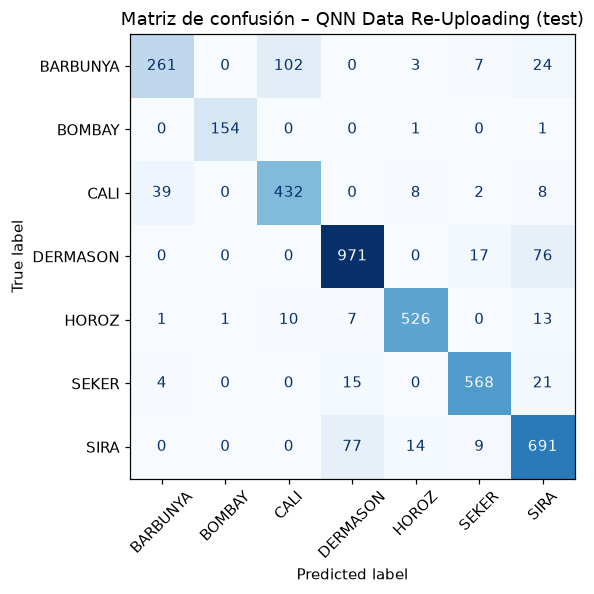

In [10]:
best_q = max(main_runs, key=lambda r: max(r["hist"]["val_f1"]))      # elegida por VALIDACION, no por test
print(f"Semilla elegida por validación: {best_q['seed']}\n")
print(classification_report(yte, best_q["pred"], target_names=class_names, digits=4))

accs = [r["test"]["acc"] for r in main_runs]; f1s = [r["test"]["f1_macro"] for r in main_runs]
print(f"QNN (3 semillas): accuracy = {np.mean(accs):.4f} ± {np.std(accs):.4f} | F1 macro = {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(yte, best_q["pred"]), display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión – QNN Data Re-Uploading (test)"); ax.grid(False); plt.tight_layout(); plt.show()

## 8. Comparación con modelos clásicos

Para que la comparación sea justa usamos:

* **Misma entrada** que el QNN (4 componentes PCA ya en $[0,\pi]$, mismas particiones) para medir el efecto del *modelo*, no de la información.
* **Capacidad comparable**: un MLP con 1 capa oculta de 6 neuronas (≈ 79 parámetros, similar a los 65 del QNN), y el clasificador de centroides (análogo clásico del *swap-test* cuántico).
* **Referencias fuertes**: SVM-RBF, Random Forest y un MLP grande (64-32), también con las **16 características originales** estandarizadas (sin PCA) para saber cuánto se pierde por comprimir a 4 qubits.

Los modelos clásicos usan los hiperparámetros por defecto (SVM `C=10`), sin ajuste sobre test.

In [11]:
S16 = StandardScaler().fit(Xtr)
F16 = lambda X: S16.transform(X)

def n_mlp_params(m):
    return int(sum(c.size for c in m.coefs_) + sum(b.size for b in m.intercepts_))

models = {
  "Centroides más cercanos (4 PCA)":  (NearestCentroid(), "pca"),
  "Regresión logística (4 PCA)":      (LogisticRegression(max_iter=2000), "pca"),
  "MLP pequeño 6 neuronas (4 PCA)":   (MLPClassifier((6,), max_iter=600, random_state=SEED), "pca"),
  "SVM RBF (4 PCA)":                  (SVC(C=10), "pca"),
  "Random Forest (4 PCA)":            (RandomForestClassifier(300, random_state=SEED, n_jobs=-1), "pca"),
  "MLP grande 64-32 (4 PCA)":         (MLPClassifier((64, 32), max_iter=600, random_state=SEED), "pca"),
  "SVM RBF (16 características)":     (SVC(C=10), "full"),
  "MLP 64-32 (16 características)":   (MLPClassifier((64, 32), max_iter=600, random_state=SEED), "full"),
  "Random Forest (16 características)": (RandomForestClassifier(300, random_state=SEED, n_jobs=-1), "full"),
}
rows, clf_preds = [], {}
for name, (m, kind) in models.items():
    Xa, Xb = (Ztr, Zte) if kind == "pca" else (F16(Xtr), F16(Xte))
    t0 = time.time(); m.fit(Xa, ytr); tt = time.time() - t0
    t0 = time.time(); pr = m.predict(Xb); ti = time.time() - t0
    clf_preds[name] = pr
    npar = n_mlp_params(m) if isinstance(m, MLPClassifier) else (m.coef_.size + m.intercept_.size if hasattr(m, "coef_") else None)
    rows.append(dict(Modelo=name, **metrics(yte, pr), params=npar, t_train_s=tt, t_pred_s=ti))

for r in main_runs:
    rows.append(dict(Modelo=f"QNN re-uploading L=4 (semilla {r['seed']}, 4 PCA)", **r["test"], params=r["n_params"],
                     t_train_s=r["time"], t_pred_s=np.nan))
res = pd.DataFrame(rows).set_index("Modelo")
display(res.sort_values("f1_macro", ascending=False).round(4))

,acc,f1_macro,f1_weighted,params,t_train_s,t_pred_s
Modelo,,,,,,
MLP 64-32 (16 características),0.9257,0.9370,0.9256,3399.0,9.2647,0.0095
SVM RBF (16 características),0.9244,0.9363,0.9245,NaN,0.4727,0.5895
Random Forest (16 características),0.9190,0.9313,0.9190,NaN,2.3108,0.1022
SVM RBF (4 PCA),0.8947,0.8975,0.8940,NaN,0.4899,0.9922
Random Forest (4 PCA),0.8892,0.8938,0.8888,NaN,2.0389,0.2096
MLP grande 64-32 (4 PCA),0.8902,0.8935,0.8902,2631.0,9.3940,0.0050
Regresión logística (4 PCA),0.8873,0.8897,0.8867,35.0,0.9943,0.0010
"QNN re-uploading L=4 (semilla 0, 4 PCA)",0.8868,0.8881,0.8858,65.0,218.6184,NaN
MLP pequeño 6 neuronas (4 PCA),0.8853,0.8869,0.8845,79.0,8.1962,0.0010


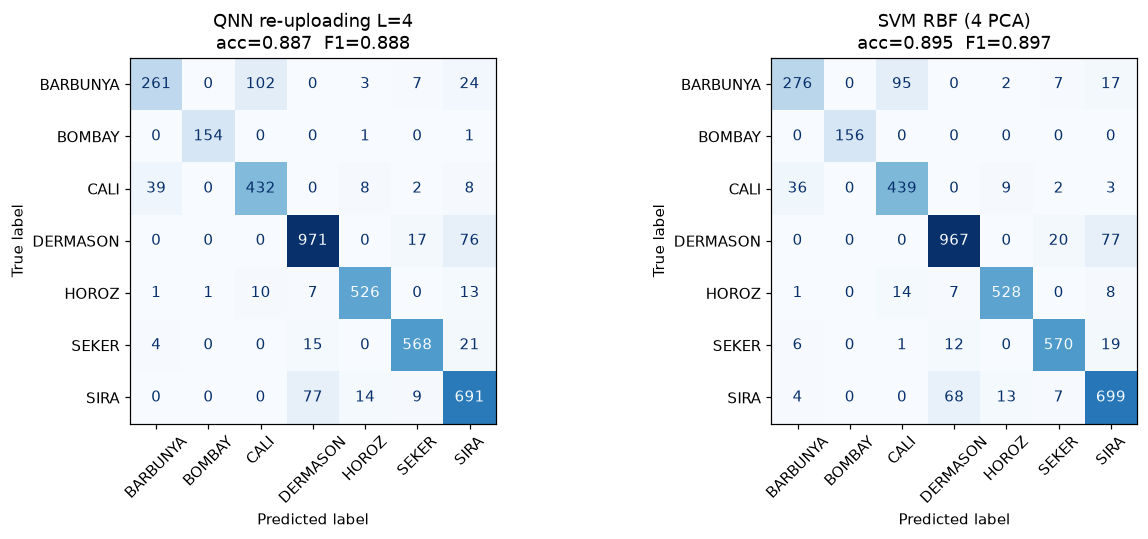

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sv = "SVM RBF (4 PCA)"
for axx, (nm, pr) in zip(ax, [("QNN re-uploading L=4", best_q["pred"]), (sv, clf_preds[sv])]):
    ConfusionMatrixDisplay(confusion_matrix(yte, pr), display_labels=class_names).plot(ax=axx, xticks_rotation=45, cmap="Blues", colorbar=False)
    axx.set_title(f"{nm}\nacc={accuracy_score(yte, pr):.3f}  F1={f1_score(yte, pr, average='macro'):.3f}"); axx.grid(False)
plt.tight_layout(); plt.show()

## 9. Ablaciones y robustez

### 9.1 ¿Importan la profundidad y la re-subida de datos?

Variamos $L\in\{1,2,4,6\}$ con re-subida y comparamos con el **VQC sin re-subida** (datos codificados una sola vez, $L=4$ capas variacionales). Mismo presupuesto de entrenamiento y una sola semilla (semilla 0).

L=1 re-upload          params= 17  tiempo=37s  acc=0.6106  F1=0.4554


L=2 re-upload          params= 33  tiempo=78s  acc=0.8632  F1=0.8579


L=6 re-upload          params= 97  tiempo=193s  acc=0.8856  F1=0.8882


L=4 sin re-upload      params= 53  tiempo=101s  acc=0.8703  F1=0.8606


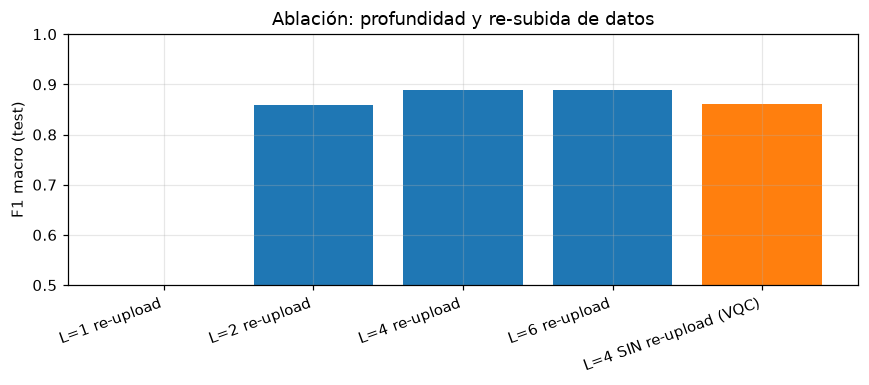

In [13]:
abl_cfg = [(1, True), (2, True), (6, True), (4, False)]
abl = {("L=4 re-upload"): main_runs[0]}
for L, ru in abl_cfg:
    r = train_qnn(L, reupload=ru, seed=0)
    pt = predict_proba(Zte, r["params"], L, ru).argmax(1)
    r["test"] = metrics(yte, pt); abl[f"L={L} {'re-upload' if ru else 'SIN re-upload (VQC)'}"] = r
    print(f"{'L=%d %s' % (L, 're-upload' if ru else 'sin re-upload'):<22} params={r['n_params']:3d}  tiempo={r['time']:.0f}s  acc={r['test']['acc']:.4f}  F1={r['test']['f1_macro']:.4f}")

order = sorted(abl, key=lambda k: (not abl[k]['reupload'], abl[k]['L']))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(len(order)), [abl[k]["test"]["f1_macro"] for k in order], color=["tab:blue" if abl[k]["reupload"] else "tab:orange" for k in order])
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_ylabel("F1 macro (test)"); ax.set_ylim(.5, 1); ax.set_title("Ablación: profundidad y re-subida de datos"); plt.tight_layout(); plt.show()

### 9.2 Efecto del número de *shots* (medición real en hardware)

En hardware no se obtienen las probabilidades exactas sino frecuencias de $S$ *shots*. Evaluamos el modelo ya entrenado (semilla elegida) con distintos $S$ sobre una submuestra de prueba de 1000 granos y comparamos con la evaluación exacta sobre la misma submuestra.

Exacto (S = infinito): acc = 0.8850


shots=   50: acc = 0.7927 ± 0.0062


shots=  200: acc = 0.8570 ± 0.0065


shots= 1000: acc = 0.8833 ± 0.0025


shots= 5000: acc = 0.8853 ± 0.0058


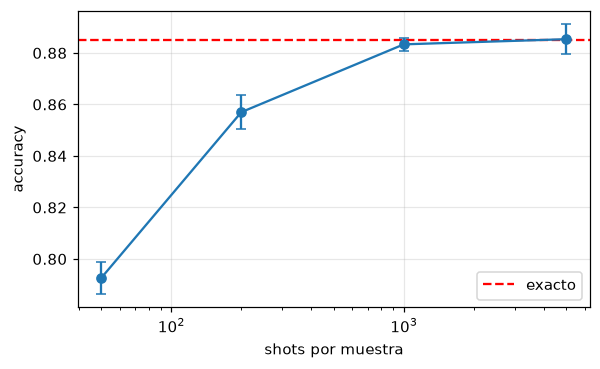

In [14]:
rng_sub = np.random.default_rng(7)
sub = rng_sub.choice(len(Zte), 1000, replace=False)
w_b, a_b, s_b = best_q["params"]
exact_acc = accuracy_score(yte[sub], predict_proba(Zte[sub], best_q["params"], L_MAIN, True).argmax(1))
print(f"Exacto (S = infinito): acc = {exact_acc:.4f}")

shot_res = {}
for S in (50, 200, 1000, 5000):
    def _c(x, w, a):
        ansatz(x, w, a, L_MAIN, True); return qml.probs(wires=range(NQ))
    circ_s = qml.set_shots(qml.QNode(_c, qml.device("default.qubit", wires=NQ, seed=123)), shots=S)
    accs_s = []
    for rep in range(3):                                   # 3 repeticiones del muestreo
        P = np.array([circ_s(z, np.asarray(w_b), np.asarray(a_b)) for z in Zte[sub]])[:, :NC]
        accs_s.append(accuracy_score(yte[sub], P.argmax(1)))
    shot_res[S] = (np.mean(accs_s), np.std(accs_s))
    print(f"shots={S:5d}: acc = {shot_res[S][0]:.4f} ± {shot_res[S][1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(list(shot_res), [v[0] for v in shot_res.values()], [v[1] for v in shot_res.values()], fmt="o-", capsize=3)
ax.axhline(exact_acc, color="r", ls="--", label="exacto"); ax.set_xscale("log")
ax.set_xlabel("shots por muestra"); ax.set_ylabel("accuracy"); ax.legend(); plt.show()

### 9.3 Costo de ejecución

Si cada muestra requiere $S$ *shots*, clasificar el conjunto de prueba (≈ 4 000 granos) cuesta $4000\cdot S$ ejecuciones de circuito, y **entrenar** con el método de regla de desplazamiento de parámetros (parameter-shift) en hardware costaría $2|\boldsymbol\theta|=130$ evaluaciones de circuito *por muestra y por paso*, frente a un único *backward pass* clásico. Mostramos la estimación:

In [15]:
n_train, n_params = len(Ztr), main_runs[0]["n_params"]
for S in (1000,):
    per_epoch = n_train * 2 * n_params * S
    print(f"Entrenamiento en hardware (parameter-shift, S={S}): {per_epoch:,} shots por época  ->  {per_epoch*EPOCHS:,.0f} shots en {EPOCHS} épocas")
print(f"Inferencia de {len(Zte)} granos con S=1000: {len(Zte)*1000:,} shots")
specs = qml.specs(probs_qnode)(Ztr[0], np.asarray(main_runs[0]['params'][0]), np.asarray(main_runs[0]['params'][1]), L_MAIN, True)
print("\nRecursos del circuito (qml.specs):"); print(specs.resources)

Entrenamiento en hardware (parameter-shift, S=1000): 1,109,160,000 shots por época  ->  22,183,200,000 shots en 20 épocas
Inferencia de 4063 granos con S=1000: 4,063,000 shots

Recursos del circuito (qml.specs):
Wire allocations: 4
Total gates: 48
Gate counts:
- RX: 16
- Rot: 16
- CNOT: 16
Measurements:
- probs(all wires): 1
Depth: 24


## 10. Conclusiones y discusión

In [16]:
q = pd.DataFrame([r["test"] for r in main_runs])
summ = res.copy()
print("QNN (media ± std, 3 semillas): acc = %.4f ± %.4f | F1 macro = %.4f ± %.4f" %
      (q.acc.mean(), q.acc.std(ddof=0), q.f1_macro.mean(), q.f1_macro.std(ddof=0)))
print("Mejor clásico 4 PCA :", summ[summ.index.str.contains("4 PCA") & ~summ.index.str.contains("QNN")]["f1_macro"].idxmax(),
      "-> F1 macro = %.4f" % summ[summ.index.str.contains("4 PCA") & ~summ.index.str.contains("QNN")]["f1_macro"].max())
print("Mejor clásico 16 car:", summ[summ.index.str.contains("16 car")]["f1_macro"].idxmax(),
      "-> F1 macro = %.4f" % summ[summ.index.str.contains("16 car")]["f1_macro"].max())

QNN (media ± std, 3 semillas): acc = 0.8839 ± 0.0022 | F1 macro = 0.8859 ± 0.0015
Mejor clásico 4 PCA : SVM RBF (4 PCA) -> F1 macro = 0.8975
Mejor clásico 16 car: MLP 64-32 (16 características) -> F1 macro = 0.9370


### 10.1 Resumen cuantitativo (conjunto de prueba, 4 063 granos)

| Modelo | Entrada | Parámetros | Accuracy | F1 macro |
|---|---|---|---|---|
| **QNN re-uploading $L=4$** (3 semillas) | 4 PCA / 4 qubits | 65 | 0.884 ± 0.002 | 0.886 ± 0.002 |
| MLP pequeño (6 neuronas) | 4 PCA | 79 | 0.885 | 0.887 |
| Regresión logística | 4 PCA | 35 | 0.887 | 0.890 |
| MLP 64-32 | 4 PCA | 2 631 | 0.890 | 0.894 |
| Random Forest | 4 PCA | – | 0.889 | 0.894 |
| SVM RBF | 4 PCA | – | 0.895 | 0.898 |
| Centroides más cercanos (análogo del *swap-test*) | 4 PCA | – | 0.804 | 0.810 |
| MLP 64-32 | 16 características | 3 399 | 0.926 | 0.937 |
| SVM RBF | 16 características | – | 0.924 | 0.936 |

*(Los valores provienen de la ejecución de este cuaderno; ver las tablas de las secciones 7–9.)*

### 10.2 Discusión

1. **El QNN funciona y es competitivo a igual información.** Con solo 4 qubits y 65 parámetros alcanza ≈ 88.4 % de *accuracy* y ≈ 0.886 de F1 macro, a ≈ 1 punto porcentual del mejor modelo clásico con la misma entrada (SVM-RBF, 0.898) y prácticamente empatado con un MLP clásico de capacidad comparable (79 parámetros, 0.887). Con 4 063 muestras de prueba el error estándar de una *accuracy* ≈ 0.89 es ≈ 0.5 %, por lo que la diferencia con modelos clásicos de la misma entrada es **marginal**, no concluyente. Es claramente mejor que el clasificador de centroides (0.810), lo que muestra que la capacidad no lineal del circuito aporta algo real.
2. **El cuello de botella es la entrada, no el modelo.** Todos los modelos con 4 componentes PCA se estancan en ≈ 0.89–0.90, mientras que usando las 16 características los clásicos llegan a ≈ 0.93–0.94 F1. Comprimir a 4 componentes (95 % de la varianza) pierde información discriminante sutil. Esto es una **restricción cuántica real**: con codificación por ángulos un qubit equivale a una característica, y escalar a 16 qubits encarece mucho la simulación y empeora la entrenabilidad (*barren plateaus*).
3. **Los errores son estructurales.** La matriz de confusión muestra que QNN y SVM fallan en los mismos pares: Barbunya↔Cali (102 Barbunya clasificados como Cali) y Dermason↔Sira (≈ 76 en cada sentido), clases morfológicamente muy solapadas en el espacio PCA de 4 dimensiones; Bombay se distingue casi perfectamente (F1 ≈ 0.99) por su tamaño extremo. Barbunya, por ser minoritaria, tiene el menor recall (0.66) y por ello el F1 macro es más informativo que la *accuracy*.
4. **La re-subida de datos y la profundidad importan (ablación).** Con $L=1$ (17 parámetros) el modelo es insuficiente (accuracy 0.61, F1 0.46); $L=2$ ya llega a 0.86; $L=4$ y $L=6$ se saturan en ≈ 0.886–0.888, por lo que más profundidad no ayuda (y $L=6$ cuesta el doble de tiempo). Con **el mismo número de capas pero sin re-subida** ($L=4$, VQC convencional, 53 parámetros) el rendimiento baja a 0.870 de *accuracy* / 0.861 de F1, esto es ≈ 2.7 puntos de F1 menos, consistente con la teoría de Fourier de Schuld et al.: re-subir los datos amplía el espectro de frecuencias del modelo. Es una sola semilla, así que la magnitud exacta es indicativa.
5. **Costo práctico (el lado desfavorable).** Entrenar el QNN en simulación tomó ≈ 150–220 s frente a 0.3–10 s de los modelos clásicos equivalentes. En hardware real, entrenar con *parameter-shift* requeriría ≈ $2\times10^{10}$ *shots* (sección 9.3), y la inferencia exige muestreo: con 50 *shots* la *accuracy* cae a ≈ 0.79, con 200 a ≈ 0.86 y solo con ≳ 1 000 *shots* se recupera el valor exacto (≈ 0.885). Es decir, el rendimiento depende del presupuesto de mediciones, algo que un modelo clásico no tiene. Tampoco modelamos ruido de compuertas, que degradaría aún más los resultados.
6. **¿Hay ventaja cuántica?** **No.** En este problema, con 4 qubits, un modelo clásico de 79 parámetros iguala al QNN y modelos clásicos con más información lo superan ampliamente, además de entrenar 10–100 veces más rápido. Un espacio de Hilbert de 16 dimensiones se simula trivialmente, de modo que no se puede esperar ventaja. El valor de este trabajo es mostrar que un clasificador variacional cuántico **muy compacto y de poca profundidad (36 de profundidad nativa, 16 CNOT)** puede resolver un problema multiclase real con rendimiento competitivo, y caracterizar honestamente sus costos y limitaciones.

### 10.3 Limitaciones y trabajo futuro

* Se usó una sola partición train/test y 3 semillas; una validación cruzada estratificada daría intervalos de confianza más sólidos.
* Los hiperparámetros del QNN (tasa, $\beta$, lectura por estados base) no se optimizaron exhaustivamente; la lectura con observables $\langle Z_i\rangle$ o pérdidas con margen podrían mejorar.
* Probar más componentes PCA (p. ej. 6–8 qubits) o una codificación que empaquete varias características por qubit, para cerrar la brecha hacia el 0.93 de las 16 características.
* Evaluar con un modelo de ruido realista (Qiskit Aer / dispositivos IBM) y con mitigación de errores.
* Implementar la alternativa de centroides cuánticos con *swap-test* y compararla con el QNN.

## 11. Referencias

1. Koklu, M., & Özkan, I. A. (2020). *Multiclass classification of dry beans using computer vision and machine learning techniques.* Computers and Electronics in Agriculture, 174, 105507. Dataset: UCI Machine Learning Repository, *Dry Bean Dataset* (DOI 10.24432/C50S4B).
2. Pérez-Salinas, A., Cervera-Lierta, A., Gil-Fuster, E., & Latorre, J. I. (2020). *Data re-uploading for a universal quantum classifier.* Quantum, 4, 226.
3. Schuld, M., Sweke, R., & Meyer, J. J. (2021). *Effect of data encoding on the expressive power of variational quantum-machine-learning models.* Phys. Rev. A, 103, 032430.
4. Havlíček, V. et al. (2019). *Supervised learning with quantum-enhanced feature spaces.* Nature, 567, 209–212.
5. McClean, J. R. et al. (2018). *Barren plateaus in quantum neural network landscapes.* Nature Communications, 9, 4812.
6. Bergholm, V. et al. (2018). *PennyLane: Automatic differentiation of hybrid quantum-classical computations.* arXiv:1811.04968.
7. Schuld, M., Bocharov, A., Svore, K. M., & Wiebe, N. (2020). *Circuit-centric quantum classifiers.* Phys. Rev. A, 101, 032308.